In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROCESSED = Path("../processed")
FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

df = pd.read_parquet(PROCESSED / "data_merged.parquet")
print(df.shape)

(590540, 434)


## Class Distribution

isFraud
0    569877
1     20663
Name: count, dtype: int64
isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64


/var/folders/wt/k04sj_gj2txbf9dld5w6kv840000gn/T/ipykernel_68626/2439050807.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="isFraud", data=df, palette=["#534AB7", "#E0574C"], ax=ax)
/var/folders/wt/k04sj_gj2txbf9dld5w6kv840000gn/T/ipykernel_68626/2439050807.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(["Legitimate", "Fraud"])


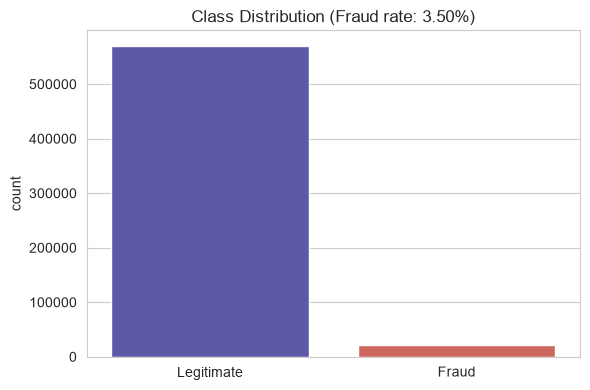

In [4]:
fraud_counts = df["isFraud"].value_counts()
fraud_pct = df["isFraud"].value_counts(normalize=True) * 100

print(fraud_counts)
print(fraud_pct)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x="isFraud", data=df, palette=["#534AB7", "#E0574C"], ax=ax)
ax.set_xticklabels(["Legitimate", "Fraud"])
ax.set_title(f"Class Distribution (Fraud rate: {fraud_pct[1]:.2f}%)")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIGURES / "01_class_distribution.png", dpi=150)
plt.show()

## TransactionAmt per Class



/var/folders/wt/k04sj_gj2txbf9dld5w6kv840000gn/T/ipykernel_68626/3796562730.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="isFraud", y="TransactionAmt", ax=axes[1],
/var/folders/wt/k04sj_gj2txbf9dld5w6kv840000gn/T/ipykernel_68626/3796562730.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["Legitimate", "Fraud"])


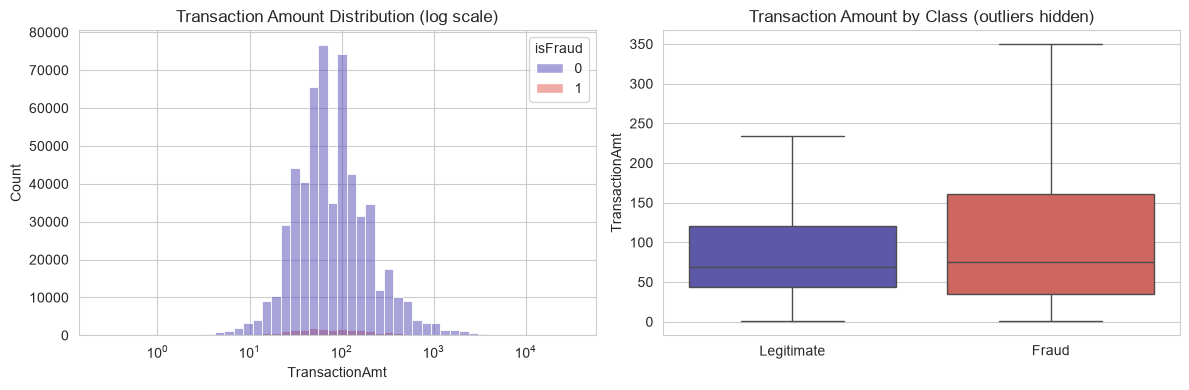

            count        mean         std    min     25%   50%    75%  \
isFraud                                                                 
0        569877.0  134.511665  239.395078  0.251  43.970  68.5  120.0   
1         20663.0  149.244779  232.212163  0.292  35.044  75.0  161.0   

               max  
isFraud             
0        31937.391  
1         5191.000  


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Complete Distribution with log scale 
sns.histplot(data=df, x="TransactionAmt", hue="isFraud", bins=50, 
             log_scale=True, ax=axes[0], palette=["#534AB7", "#E0574C"])
axes[0].set_title("Transaction Amount Distribution (log scale)")

# Boxplot to compare medians/IQR
sns.boxplot(data=df, x="isFraud", y="TransactionAmt", ax=axes[1],
            palette=["#534AB7", "#E0574C"], showfliers=False)
axes[1].set_xticklabels(["Legitimate", "Fraud"])
axes[1].set_title("Transaction Amount by Class (outliers hidden)")
axes[1].set_xlabel("")

plt.tight_layout()
plt.savefig(FIGURES / "02_amount_by_class.png", dpi=150)
plt.show()

print(df.groupby("isFraud")["TransactionAmt"].describe())

## Fraud Rate by Product CD


           fraud_rate  n_transactions
ProductCD                            
C            0.116873           68519
S            0.058996           11628
H            0.047662           33024
R            0.037826           37699
W            0.020399          439670


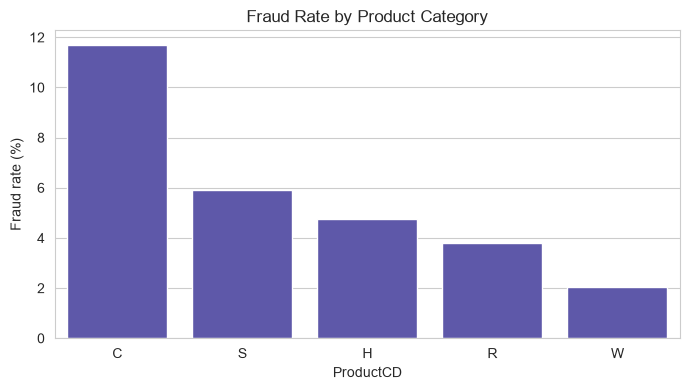

In [6]:
fraud_by_product = df.groupby("ProductCD")["isFraud"].agg(["mean", "count"]).sort_values("mean", ascending=False)
fraud_by_product.columns = ["fraud_rate", "n_transactions"]
print(fraud_by_product)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=fraud_by_product.index, y=fraud_by_product["fraud_rate"]*100, 
            color="#534AB7", ax=ax)
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud Rate by Product Category")
plt.tight_layout()
plt.savefig(FIGURES / "03_fraud_by_product.png", dpi=150)
plt.show()

## Fraud Rate by Card type

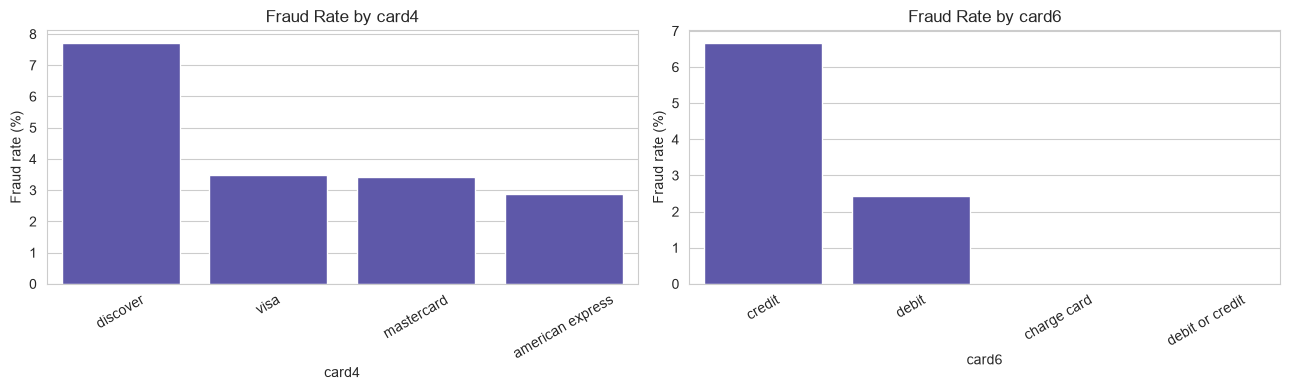

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(axes, ["card4", "card6"]):
    rate = df.groupby(col)["isFraud"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.index, y=rate.values, color="#534AB7", ax=ax)
    ax.set_ylabel("Fraud rate (%)")
    ax.set_title(f"Fraud Rate by {col}")
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(FIGURES / "04_fraud_by_card_type.png", dpi=150)
plt.show()

## Transactions over time

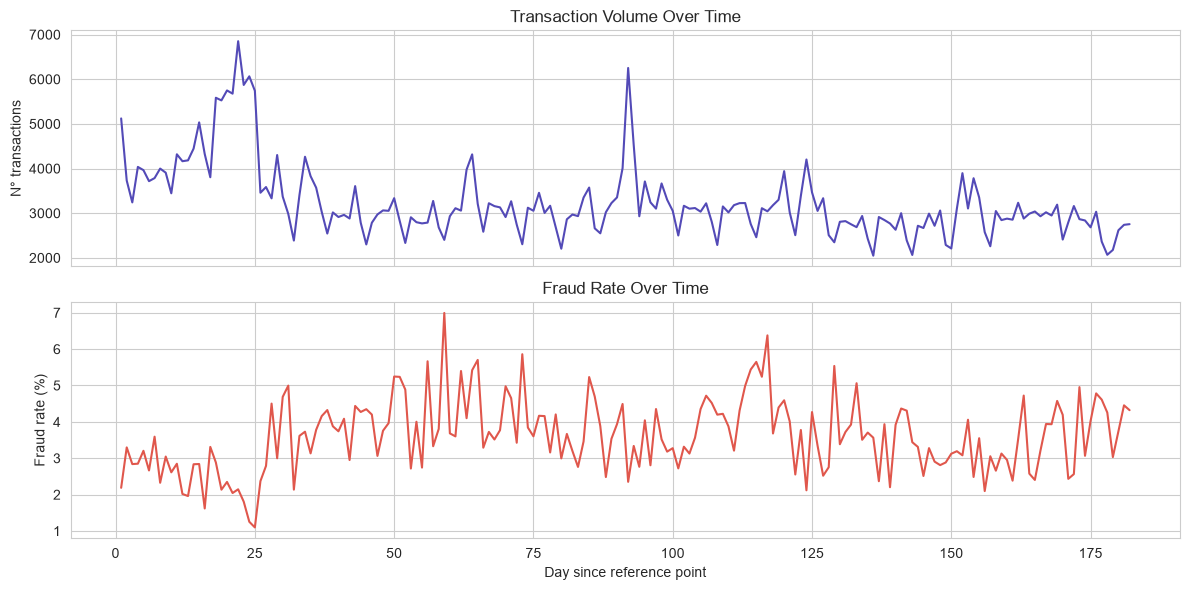

In [8]:
df["day"] = df["TransactionDT"] / (24 * 60 * 60)

daily_fraud = df.groupby(df["day"].astype(int))["isFraud"].agg(["mean", "count"])
daily_fraud.columns = ["fraud_rate", "n_transactions"]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(daily_fraud.index, daily_fraud["n_transactions"], color="#534AB7")
axes[0].set_ylabel("N° transactions")
axes[0].set_title("Transaction Volume Over Time")

axes[1].plot(daily_fraud.index, daily_fraud["fraud_rate"]*100, color="#E0574C")
axes[1].set_ylabel("Fraud rate (%)")
axes[1].set_xlabel("Day since reference point")
axes[1].set_title("Fraud Rate Over Time")

plt.tight_layout()
plt.savefig(FIGURES / "05_temporal_pattern.png", dpi=150)
plt.show()

In [9]:
print(df["card6"].value_counts())
print()
print(df.groupby("card6")["isFraud"].agg(["mean", "count"]))

card6
debit              439938
credit             148986
debit or credit        30
charge card            15
Name: count, dtype: int64

                     mean   count
card6                            
charge card      0.000000      15
credit           0.066785  148986
debit            0.024263  439938
debit or credit  0.000000      30


In [10]:
spike_window = df[(df["day"] >= 18) & (df["day"] <= 26)]
print(f"Transactions in spike window: {len(spike_window)}")
print(f"Fraud rate in spike window: {spike_window['isFraud'].mean()*100:.2f}%")
print(f"Fraud rate overall: {df['isFraud'].mean()*100:.2f}%")

# Compare product mix during spike vs overall
print("\nProductCD mix during spike:")
print(spike_window["ProductCD"].value_counts(normalize=True))
print("\nProductCD mix overall:")
print(df["ProductCD"].value_counts(normalize=True))

Transactions in spike window: 47068
Fraud rate in spike window: 1.96%
Fraud rate overall: 3.50%

ProductCD mix during spike:
ProductCD
W    0.410427
R    0.266274
H    0.183246
C    0.121994
S    0.018059
Name: proportion, dtype: float64

ProductCD mix overall:
ProductCD
W    0.744522
C    0.116028
R    0.063838
H    0.055922
S    0.019690
Name: proportion, dtype: float64


In [11]:
print(df.groupby("ProductCD")["isFraud"].agg(["mean", "count"]).sort_values("mean", ascending=False))

               mean   count
ProductCD                  
C          0.116873   68519
S          0.058996   11628
H          0.047662   33024
R          0.037826   37699
W          0.020399  439670


## Summary

- Class imbalance confirmed: 3.50% fraud rate overall.
- **Transaction amount**: fraudulent transactions show a different distribution 
  pattern than legitimate ones (see `02_amount_by_class.png`), though with 
  significant overlap — amount alone isn't a strong fraud signal.
- **Card type matters**: Discover cards show a fraud rate of ~7.7% vs. ~3.5% 
  for Visa/Mastercard. Credit cards show ~6.7% fraud rate vs. 2.4% for debit — 
  consistent with credit's lower transaction friction for fraudsters.
- **ProductCD is a strong fraud signal**: fraud rate ranges from 2.04% (`W`, 
  the dominant product at 74% of volume) to 11.69% (`C`, only 12% of volume). 
  This is one of the most predictive categorical features in the dataset.
- **Temporal pattern**: a transaction volume spike around day 20-26 (peaking 
  near 7,000/day vs. ~3,000 baseline) was investigated. Counter-intuitively, 
  fraud rate *dropped* during this spike (1.96% vs. 3.50% overall) — driven 
  by a shift in product mix toward `R` and `H` (lower-baseline-risk products) 
  and away from `C` and `W`. This illustrates why raw fraud-rate trends must 
  be decomposed by product mix before drawing conclusions — a pattern that 
  will resurface in the concept drift analysis (`07_model_monitoring.ipynb`).
- Fraud rate also rises and stabilizes at a higher baseline (~3-5%) after 
  day ~25 compared to before it, suggesting a regime shift worth monitoring 
  in production.

**Outputs:** `figures/01-05_*.png`